# Practical 2 - Foundations of Statistics (Descriptive Statistics)
Dataset: Wine chemistry - 178 Italian wines from three cultivars

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
def find_data(name):
    """Look for the CSV in the usual places; in Colab, ask for an upload if it is missing."""
    folders = (HERE.parent / "Datasets", HERE / "Datasets", HERE, Path.cwd(),
               Path("/content"), Path("/content/Datasets"), Path("/content/drive/MyDrive"))
    for folder in folders:
        if (folder / name).exists():
            return folder
    try:
        from google.colab import files
        print(f"{name} not found - please choose it in the upload dialog (it is in the Datasets folder).")
        files.upload()
        return Path.cwd()
    except ImportError:
        raise FileNotFoundError(f"Could not find {name}. Put it in a 'Datasets' folder next to this script.")

DATA = find_data("wine.csv")
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

wine = pd.read_csv(DATA / "wine.csv")
print("Shape            :", wine.shape)
print("Columns          :", list(wine.columns))
print("Missing values   :", int(wine.isna().sum().sum()))
print("Wines per class  :")
print(wine["wine_class"].value_counts().to_string())

Shape            : (178, 14)
Columns          : ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'wine_class']
Missing values   : 0
Wines per class  :
wine_class
class_1    71
class_0    59
class_2    48


## 1. What kind of dataset is this?
Every row is a different wine measured once, there is no time column, so the data is **cross-sectional**.

In [2]:
has_time_axis = any("date" in c.lower() or "year" in c.lower() for c in wine.columns)
print("Time column present :", has_time_axis)
print("Dataset type        :", "time series / panel" if has_time_axis else "cross-sectional")

Time column present : False
Dataset type        : cross-sectional


## 2. Centre and spread of one variable (proline)

In [3]:
proline = wine["proline"]
centre_spread = {
    "mean": proline.mean(),
    "median": proline.median(),
    "minimum": proline.min(),
    "maximum": proline.max(),
    "range": proline.max() - proline.min(),
    "std dev": proline.std(),
    "IQR": proline.quantile(0.75) - proline.quantile(0.25),
}
for name, value in centre_spread.items():
    print(f"{name:<8}: {value:10.3f}")

mean    :    746.893
median  :    673.500
minimum :    278.000
maximum :   1680.000
range   :   1402.000
std dev :    314.907
IQR     :    484.500


## 3. Descriptive-statistics table

In [4]:
table = wine.drop(columns="wine_class").describe().T
table["cv_%"] = 100 * table["std"] / table["mean"]
print(table[["count", "mean", "std", "min", "50%", "max", "cv_%"]].round(3).to_string())

                              count     mean      std     min      50%      max    cv_%
alcohol                       178.0   13.001    0.812   11.03   13.050    14.83   6.245
malic_acid                    178.0    2.336    1.117    0.74    1.865     5.80  47.816
ash                           178.0    2.367    0.274    1.36    2.360     3.23  11.593
alcalinity_of_ash             178.0   19.495    3.340   10.60   19.500    30.00  17.130
magnesium                     178.0   99.742   14.282   70.00   98.000   162.00  14.319
total_phenols                 178.0    2.295    0.626    0.98    2.355     3.88  27.269
flavanoids                    178.0    2.029    0.999    0.34    2.135     5.08  49.223
nonflavanoid_phenols          178.0    0.362    0.124    0.13    0.340     0.66  34.393
proanthocyanins               178.0    1.591    0.572    0.41    1.555     3.58  35.977
color_intensity               178.0    5.058    2.318    1.28    4.690    13.00  45.833
hue                           17

## 4. Shape of the alcohol distribution

Mean     : 13.0006
Median   : 13.0500
Std dev  : 0.8118
Skewness : -0.0515
Kurtosis : -0.8525
Comment: the alcohol distribution is roughly symmetric


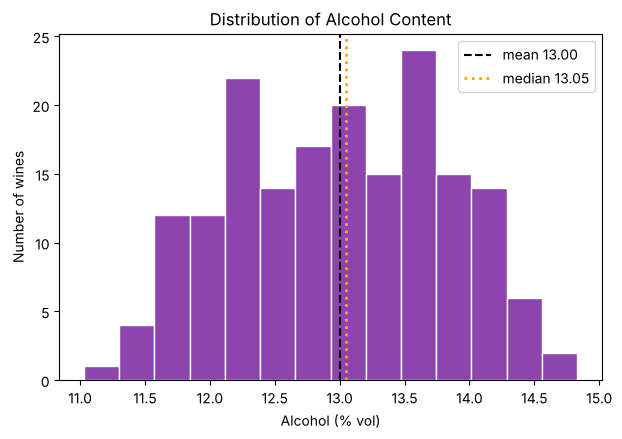

In [5]:
alc = wine["alcohol"]
print(f"Mean     : {alc.mean():.4f}")
print(f"Median   : {alc.median():.4f}")
print(f"Std dev  : {alc.std():.4f}")
print(f"Skewness : {alc.skew():.4f}")
print(f"Kurtosis : {alc.kurt():.4f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(alc, bins=14, color="#8e44ad", edgecolor="white")
ax.axvline(alc.mean(), color="black", linestyle="--", label=f"mean {alc.mean():.2f}")
ax.axvline(alc.median(), color="orange", linestyle=":", linewidth=2, label=f"median {alc.median():.2f}")
ax.set(title="Distribution of Alcohol Content", xlabel="Alcohol (% vol)", ylabel="Number of wines")
ax.legend()
fig.savefig(FIG / "alcohol_histogram.png", dpi=120, bbox_inches="tight")
plt.show()

skew = alc.skew()
shape = "roughly symmetric" if abs(skew) < 0.5 else ("right-skewed" if skew > 0 else "left-skewed")
print("Comment: the alcohol distribution is", shape)

## 5. Group-wise statistics

In [6]:
by_class = wine.groupby("wine_class").agg(
    wines=("alcohol", "size"),
    alcohol_mean=("alcohol", "mean"),
    alcohol_std=("alcohol", "std"),
    flavanoids_mean=("flavanoids", "mean"),
    colour_mean=("color_intensity", "mean"),
)
print(by_class.round(3).to_string())

            wines  alcohol_mean  alcohol_std  flavanoids_mean  colour_mean
wine_class                                                                
class_0        59        13.745        0.462            2.982        5.528
class_1        71        12.279        0.538            2.081        3.087
class_2        48        13.154        0.530            0.781        7.396


## 6. Cross-tabulation: wine class vs alcohol level

In [7]:
cutoff = wine["alcohol"].median()
wine["alcohol_level"] = np.where(wine["alcohol"] >= cutoff, "high", "low")
print(f"(median alcohol used as cut-off: {cutoff})\n")

counts = pd.crosstab(wine["wine_class"], wine["alcohol_level"])
print("Counts:")
print(counts.to_string())

percent = pd.crosstab(wine["wine_class"], wine["alcohol_level"], normalize="index") * 100
print("\nRow percentages:")
print(percent.round(2).to_string())

(median alcohol used as cut-off: 13.05)

Counts:
alcohol_level  high  low
wine_class              
class_0          57    2
class_1           7   64
class_2          27   21

Row percentages:
alcohol_level   high    low
wine_class                 
class_0        96.61   3.39
class_1         9.86  90.14
class_2        56.25  43.75


## 7. Spotting outliers with the 1.5 x IQR rule

In [8]:
q1, q3 = wine["magnesium"].quantile([0.25, 0.75])
low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
flagged = wine[(wine["magnesium"] < low) | (wine["magnesium"] > high)]
print(f"Magnesium fence: [{low:.1f}, {high:.1f}]")
print("Outlying wines  :", len(flagged))
print(flagged[["wine_class", "magnesium"]].to_string())

Magnesium fence: [59.5, 135.5]
Outlying wines  : 4
   wine_class  magnesium
69    class_1      151.0
73    class_1      139.0
78    class_1      136.0
95    class_1      162.0
